# Forecasting hourly bike rentals in Seoul

At the start of an hour, how accurately can the bike-share operator predict the number of rentals citywide? Does adding the rental count from one hour, one day and one week earlier improve on a calendar-only model? Calendar patterns can capture a regular evening peak. Recent counts might capture a quieter or busier day than usual.

The forecast covers the coming hour and assumes the count for the previous hour is already available. The outcome is completed rentals, including hours when the system was closed. The primary metric is **mean absolute error** in rentals per hour. A mean absolute error of 100 corresponds to missing the observed count by 100 rentals per forecast hour on average.

## Data and forecast timing

The Seoul Bike Sharing Demand dataset records the number of public bike rentals each hour, along with weather, holiday and operating-status fields. It contains one citywide count per hour from December 2017 through November 2018. At prediction time the hour, weekday and holiday are known. Weather in this file was measured during the target hour, so the models use calendar information and past rental counts. The operating flag is used to describe closures. [Easwaramoorthy (2020), UCI Machine Learning Repository](https://doi.org/10.24432/C5F62R)

Run the notebook from the top with Python, pandas, NumPy, Matplotlib and scikit-learn in Jupyter. The first cell downloads the source from UCI. It can also read an original `SeoulBikeData.csv` placed beside the notebook.

In [1]:
from io import BytesIO
from pathlib import Path
from time import perf_counter
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

source_url = "https://archive.ics.uci.edu/static/public/560/seoul+bike+sharing+demand.zip"
csv_path = Path("SeoulBikeData.csv")
if csv_path.is_file():
	data = csv_path.read_bytes()
else:
	with urlopen(source_url, timeout=30) as response, ZipFile(BytesIO(response.read())) as archive:
		data = archive.read(csv_path.name)

raw = pd.read_csv(BytesIO(data), encoding="cp1252")
hours = pd.to_datetime(raw["Date"], format="%d/%m/%Y") + pd.to_timedelta(raw["Hour"], unit="h")
bikes = raw.set_index(hours).sort_index().rename_axis("time")
bikes = bikes.rename(columns={"Rented Bike Count": "rentals"})
assert bikes.index.equals(pd.date_range(bikes.index.min(), bikes.index.max(), freq="h"))
assert bikes[["rentals", "Holiday", "Functioning Day"]].notna().all().all()
assert bikes["rentals"].ge(0).all()
print(f"{len(bikes):,} consecutive hours from {bikes.index.min()} to {bikes.index.max()}.")

8,760 consecutive hours from 2017-12-01 00:00:00 to 2018-11-30 23:00:00.


## Chronological split

December through July supplies the training history. August and September form the validation period for comparing the models. October and November are reserved for the final evaluation. Each prediction uses the counts already observed by that hour. This allows an observed count from Monday to inform Tuesday's forecast even when both days fall in validation.

Each lag is formed on the complete, ordered hourly index. The first week lacks a weekly lag, so every model starts on the same date. Closure hours stay in the timeline because the system recorded zero completed rentals during those hours.

In [2]:
frame = bikes[["rentals"]].copy()
frame["hour_of_week"] = frame.index.day_of_week * 24 + frame.index.hour
frame["holiday"] = bikes["Holiday"]
lag_hours = [1, 24, 168]
lag_features = [f"lag_{hours_back}h" for hours_back in lag_hours]
for hours_back, column in zip(lag_hours, lag_features):
	frame[column] = frame["rentals"].shift(hours_back)

frame = frame.dropna(subset=lag_features)
train = frame.loc[frame.index < "2018-08-01"].copy()
valid = frame.loc[(frame.index >= "2018-08-01") & (frame.index < "2018-10-01")].copy()
test = frame.loc[frame.index >= "2018-10-01"].copy()
assert train.index.max() < valid.index.min() <= valid.index.max() < test.index.min()
assert len(train) + len(valid) + len(test) == len(bikes) - max(lag_hours)

splits = {"Training": train, "Validation": valid, "Final test": test}
pd.DataFrame([
	{
		"Split": name,
		"First day": rows.index.min().date(),
		"Last day": rows.index.max().date(),
		"Hourly forecasts": len(rows),
	}
	for name, rows in splits.items()
]).set_index("Split")

,First day,Last day,Hourly forecasts
Split,,,
Training,2017-12-08,2018-07-31,5664
Validation,2018-08-01,2018-09-30,1464
Final test,2018-10-01,2018-11-30,1464


## What patterns are visible in training?

The daily series shows how far demand moves across months. The hourly profiles compare weekdays and weekends, averaging observed rentals across all training dates in each group.

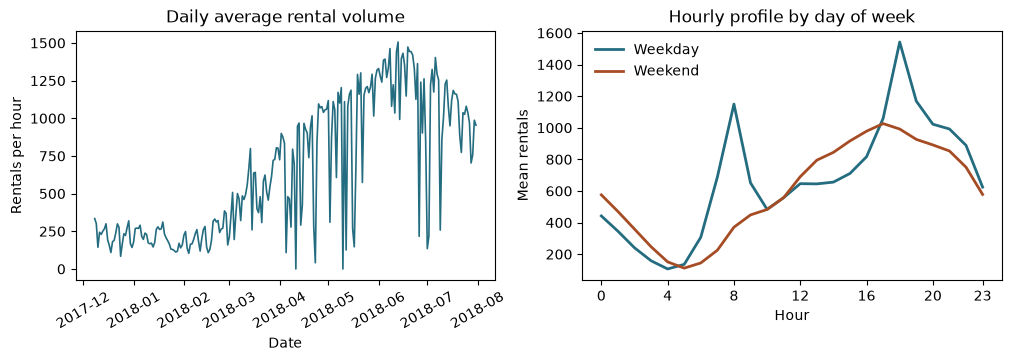

Closed training hours: 48 of 5,664.
Peak hour by day type: {'Weekday': 18, 'Weekend': 17}


In [3]:
daily_rentals = train["rentals"].resample("D").mean()
day_type = np.where(train.index.day_of_week < 5, "Weekday", "Weekend")
profile = train.groupby([train.index.hour, day_type])["rentals"].mean().unstack()

fig, (trend, hourly) = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
trend.plot(daily_rentals.index, daily_rentals, color="#246c80", linewidth=1.2)
trend.set(title="Daily average rental volume", ylabel="Rentals per hour", xlabel="Date")
trend.tick_params(axis="x", labelrotation=30)
for label, color in [("Weekday", "#246c80"), ("Weekend", "#a64c24")]:
	hourly.plot(profile.index, profile[label], label=label, color=color, linewidth=2)
hourly.set(title="Hourly profile by day of week", xlabel="Hour", ylabel="Mean rentals")
hourly.set_xticks([0, 4, 8, 12, 16, 20, 23])
hourly.legend(frameon=False)
plt.show()

closed = bikes.loc[train.index, "Functioning Day"].eq("No")
print(f"Closed training hours: {closed.sum()} of {len(train):,}.")
print("Peak hour by day type:", profile.idxmax().to_dict())

The weekday profile peaks at 18:00, one hour later than the weekend profile. The daily series also rises markedly from winter into summer. The same weekday and hour can therefore have different rental volumes across the training period.

## Baseline forecasts

The **previous-hour baseline** repeats the last observed count. It is a useful benchmark when demand changes gradually. The **calendar ridge regression** learns a separate effect for each of the 168 hours of the week and a holiday effect. The **calendar and history ridge regression** adds the three lagged counts. Comparing the two regressions isolates how much the observed history helps.

The ridge regressions use a fixed ridge penalty of 1. The penalty shrinks the fitted coefficients toward zero, and the numerical lag features are standardized using the training period. Predictions have a lower bound of zero because rental counts cannot be negative.

### A different previous-hour slope for each time of day

In history ridge, an extra 100 rentals in the previous hour changes the prediction by the same amount at every hour. Time-interaction ridge adds one adjustment to that slope for each clock hour on weekdays and each clock hour on weekends (48 groups). A weekday morning can therefore respond differently to the same recent demand than a weekend morning. The global lag slope, the 24-hour and 168-hour lags, the calendar terms and the ridge penalty stay the same. The group adjustments use the previous count standardized on training data. Shrinking the adjustments toward zero lets each group borrow the global slope.

In [4]:
calendar_features = ["hour_of_week", "holiday"]


def lag_by_time_group(values: np.ndarray) -> np.ndarray:
    """Activate one standardized lag term for the forecast hour and day type."""
    hour_of_week = values[:, 0].astype(int)
    hour = hour_of_week % 24
    is_weekend = hour_of_week >= 5 * 24
    group = hour + 24 * is_weekend
    standardized_lag = values[:, 1]
    return (group[:, None] == np.arange(48)) * standardized_lag[:, None]


def rental_model(history_features: list[str], *, varying_hourly_slope: bool = False) -> Pipeline:
    """Build a ridge regression for the calendar and the specified rental-count lags."""
    terms = [
        ("calendar", OneHotEncoder(handle_unknown="ignore"), calendar_features),
        ("history", StandardScaler(), history_features),
    ]
    if varying_hourly_slope:
        group_and_lag = ColumnTransformer([
            ("group", "passthrough", ["hour_of_week"]),
            ("lag", StandardScaler(), ["lag_1h"]),
        ])
        interactions = make_pipeline(group_and_lag, FunctionTransformer(lag_by_time_group))
        terms.append(("hourly_slope", interactions, ["hour_of_week", "lag_1h"]))
    return make_pipeline(ColumnTransformer(terms), Ridge(alpha=1.0, solver="lsqr"))


models = {
    "Calendar ridge": rental_model([]),
    "Calendar + history ridge": rental_model(lag_features),
    "Time-interaction ridge": rental_model(lag_features, varying_hourly_slope=True),
}
predictors = calendar_features + lag_features

### Does the previous hour mean the same thing at every hour of the day?

History ridge gives the previous count a single coefficient across all 168 hours of the week. A boosted tree can first split by time of day, then learn a different response to recent demand within each branch. For example, the same 08:00 count can precede different 09:00 demand on weekdays and weekends.

The tree uses the same information as history ridge. We recover hour and weekday from the existing hour-of-week value so that a single split can group mornings across days. We encode holiday as a binary flag and keep all three lagged counts in their original units. We fix 100 boosting rounds, depth 3, a learning rate of 0.1 and a minimum of 20 training hours per leaf. Each tree fits residuals under squared-error loss. Shallow trees limit how finely the model can split rare time-and-demand combinations. We fit once through July with early stopping disabled, then compare forecasts by August–September MAE. The printed time measures one local fit, including preprocessing.

In [5]:
def tree_features(rows: pd.DataFrame) -> pd.DataFrame:
    hour_of_week = rows["hour_of_week"]
    return rows[lag_features].assign(
        hour=hour_of_week % 24,
        weekday=hour_of_week // 24,
        holiday=rows["holiday"].eq("Holiday").astype(int),
    )


models["History gradient boosting"] = make_pipeline(
    FunctionTransformer(tree_features, validate=False),
    HistGradientBoostingRegressor(
        loss="squared_error",
        max_iter=100,
        max_depth=3,
        learning_rate=0.1,
        min_samples_leaf=20,
        early_stopping=False,
        random_state=42,
    ),
)

for name, model in models.items():
    start_time = perf_counter()
    model.fit(train[predictors], train["rentals"])
    print(f"{name}: {perf_counter() - start_time:.3f} s to fit {len(train):,} hours")

Calendar ridge: 0.192 s to fit 5,664 hours
Calendar + history ridge: 0.020 s to fit 5,664 hours
Time-interaction ridge: 0.037 s to fit 5,664 hours
History gradient boosting: 0.141 s to fit 5,664 hours


## Validation results

All five methods predict the same hours. The table shows MAE in rentals per hour for each validation month and for the full period. Each hour has equal weight in the pooled score. A lower mean absolute error means fewer rentals missed per forecast on average.

In [6]:
valid_predictions = pd.DataFrame({"Previous hour": valid["lag_1h"]}, index=valid.index)
for name, model in models.items():
	valid_predictions[name] = np.maximum(0, model.predict(valid[predictors]))

absolute_errors = valid_predictions.sub(valid["rentals"], axis="index").abs()
validation_mae = absolute_errors.mean()
monthly_mae_by_model = absolute_errors.groupby(valid.index.strftime("%B"), sort=False).mean().T
monthly_mae_by_model["August and September"] = validation_mae
monthly_mae_by_model.round(1)

time,August,September,August and September
Previous hour,215.4,224.7,220.0
Calendar ridge,338.3,546.2,440.6
Calendar + history ridge,113.2,159.5,136.0
Time-interaction ridge,87.4,94.6,91.0
History gradient boosting,111.5,118.7,115.1


On validation, adding the three historical counts reduced mean absolute error from 440.6 to 136.0 rentals per hour. Even repeating the last count (220.0) beat the calendar model. The combined model also beat that baseline by 84.0 rentals per hour. The comparison measures the contribution of the three lags together across August and September.

On the same 1,464 validation hours, boosting reduced MAE from 136.0 for history ridge to 114.8 rentals per hour. This is 21.2 fewer rentals missed per hourly forecast on average (15.6%). Both models use the same calendar and rental history. Time-interaction ridge lowers the pooled MAE further to 91.0 rentals per hour. Its error is lower than boosting in both August (87.4 versus 112.0) and September (94.6 versus 117.7). Both comparison models are ready for the final refit.

## How much does each part of the rental history add?

The fixed split above evaluates one model fit across two months. To see whether the result depends on the forecast month, repeat the experiment at the beginning of June, July, August and September 2018. Each fit uses all eligible hours strictly before that month and predicts each hour in the month ahead as its preceding observations become available. The models share the same training dates, calendar features, ridge penalty and forecast hours.

Start with the calendar model, add the previous hour, then add the same hour yesterday and finally the same hour last week. Differences between adjacent rows measure the extra predictive value of each lag **in that order**. The pooled column weights each forecast hour equally.

In [7]:
lag_sets = {
	"Calendar only": [],
	"Calendar + last hour": ["lag_1h"],
	"Calendar + last hour and day": ["lag_1h", "lag_24h"],
	"Calendar + last hour, day and week": lag_features,
}
development = pd.concat([train, valid])
monthly_errors = []
for start in pd.date_range("2018-06-01", "2018-09-01", freq="MS"):
	end = start + pd.offsets.MonthBegin(1)
	past = development.loc[development.index < start]
	month = development.loc[(development.index >= start) & (development.index < end)]
	assert past.index.max() < month.index.min()
	errors = pd.DataFrame(index=month.index)
	for label, lags in lag_sets.items():
		model = rental_model(lags)
		model.fit(past[predictors], past["rentals"])
		forecast = np.maximum(0, model.predict(month[predictors]))
		errors[label] = (month["rentals"] - forecast).abs()
	monthly_errors.append(errors)

rolling_errors = pd.concat(monthly_errors)
month_labels = pd.DatetimeIndex(rolling_errors.index).strftime("%Y-%m")
monthly_mae = rolling_errors.groupby(month_labels).mean().T
monthly_mae["Pooled"] = rolling_errors.mean()
monthly_mae.round(1)

time,2018-06,2018-07,2018-08,2018-09,Pooled
Calendar only,791.7,481.6,338.3,531.0,533.6
Calendar + last hour,210.4,140.1,114.5,153.1,154.1
Calendar + last hour and day,202.6,135.4,113.6,155.6,151.4
"Calendar + last hour, day and week",198.8,136.4,113.2,156.9,150.9


Across 2,928 development hours, the error drops from 533.6 to 154.1 rentals per hour when the model gets the previous hour's count. Adding the daily and weekly lags brings it to 150.9. The previous-hour lag helps in all four months. In September, however, adding the two longer lags increases error from 153.1 to 156.9.

## When does the previous-hour baseline fall behind?

For the original August–September validation period, group absolute errors by the local hour of the forecast. The two curves compare the same observations with the models fitted through July. A previous-hour forecast can lag behind a rapid change in demand even when it tracks the day's overall level.

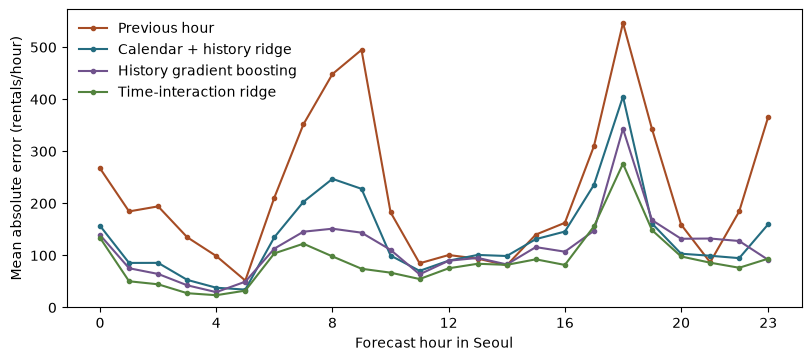

The history model improves on persistence at 21 of 24 hours.
Largest mean error reduction: 266.9 rentals at 09:00.


,Hours,Rentals at 08:00,Rentals at 09:00,Previous-hour absolute error,History ridge absolute error,Boosting absolute error,Interaction ridge absolute error
Day,,,,,,,
Weekday,43,1452.9,805.3,657.2,294.1,152.9,82.8
Weekend,18,598.3,705.2,106.8,69.8,121.9,54.5


In [8]:
methods = [
    "Previous hour",
    "Calendar + history ridge",
    "History gradient boosting",
    "Time-interaction ridge",
]
pair_errors = valid_predictions[methods].sub(valid["rentals"], axis="index").abs()
hourly_mae = pair_errors.groupby(valid.index.hour).mean()

fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
for method, color in zip(methods, ["#a64c24", "#246c80", "#70528c", "#53833e"]):
	ax.plot(hourly_mae.index, hourly_mae[method], label=method, color=color, marker=".")
ax.set(xlabel="Forecast hour in Seoul", ylabel="Mean absolute error (rentals/hour)")
ax.set_xticks([0, 4, 8, 12, 16, 20, 23])
ax.set_ylim(bottom=0)
ax.legend(frameon=False)
plt.show()

gain_by_hour = hourly_mae["Previous hour"] - hourly_mae["Calendar + history ridge"]
print(f"The history model improves on persistence at {gain_by_hour.gt(0).sum()} of 24 hours.")
best_hour = gain_by_hour.idxmax()
print(f"Largest mean error reduction: {gain_by_hour.max():.1f} rentals at {best_hour:02}:00.")

nine_am = valid.index.hour == 9
morning = pd.DataFrame({
	"Day": np.where(valid.index[nine_am].day_of_week < 5, "Weekday", "Weekend"),
	"Rentals at 08:00": valid.loc[nine_am, "lag_1h"],
	"Rentals at 09:00": valid.loc[nine_am, "rentals"],
	"Previous-hour absolute error": pair_errors.loc[nine_am, "Previous hour"],
	"History ridge absolute error": pair_errors.loc[nine_am, "Calendar + history ridge"],
	"Boosting absolute error": pair_errors.loc[nine_am, "History gradient boosting"],
	"Interaction ridge absolute error": pair_errors.loc[nine_am, "Time-interaction ridge"],
})
morning_summary = morning.groupby("Day").mean().round(1)
morning_summary.insert(0, "Hours", morning.groupby("Day").size())
morning_summary

In [9]:
# Compare fitted slopes using a weekday and weekend 09:00 input from training.
training_mornings = train.loc[train.index.hour == 9, predictors]
day_types = np.where(training_mornings.index.dayofweek < 5, "Weekday", "Weekend")
examples = training_mornings.groupby(day_types).first()
busier_mornings = examples.assign(lag_1h=examples["lag_1h"] + 100)
slope_examples = pd.DataFrame(index=examples.index)
for name in ["Calendar + history ridge", "Time-interaction ridge"]:
    fitted = models[name]
    slope_examples[name] = fitted.predict(busier_mornings) - fitted.predict(examples)
slope_examples.rename_axis("09:00 forecast change for 100 more rentals at 08:00").round(1)

C:\Users\21126\AppData\Local\Temp\ipykernel_15524\105618054.py:3: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  day_types = np.where(training_mornings.index.dayofweek < 5, "Weekday", "Weekend")


,Calendar + history ridge,Time-interaction ridge
09:00 forecast change for 100 more rentals at 08:00,,
Weekday,86.5,50.4
Weekend,86.5,109.5


At 09:00 on weekdays, rentals fall from an average of 1,453 in the previous hour to 805. Repeating the previous count misses this drop, with a mean absolute error of 657. The history model cuts that error to 294. On weekends, demand rises from 598 to 705 across the same two hours and the baseline error is much smaller (107). The day-of-week profile helps explain why an hour's typical change matters alongside its most recent count.

At 09:00, boosting reduced weekday MAE from 294.1 to 156.3 across 43 mornings. On the 18 weekend mornings, ridge had the smaller error (69.8 versus 80.8). The overall improvement therefore conceals a tradeoff even within one forecast hour. Time-interaction ridge lowered MAE to 82.8 on weekdays and 54.5 on weekends. These averages describe the validation period.

Holding the other inputs fixed, an additional 100 rentals at 08:00 raises ordinary history ridge's 09:00 forecast by 86.5. Time-interaction ridge raises it by 50.4 on weekdays and 109.5 on weekends. These are fitted model responses before clipping predictions at zero.

## Final evaluation on October and November

The five methods and their settings were fixed on the validation months before any test hour was scored. Nothing below changes a model setting. Each learned method is refit on every eligible hour from 8 December through 30 September. Its encoder, scalers and trees therefore see only data observed before the test period. The models then forecast the 1,464 hours from 1 October to 30 November. At each hour the previous hour's observed count is available, and predictions are clipped at zero as before. The previous-hour baseline needs no fitting.

The table reports mean absolute error in rentals per hour for each test month and for the full period. For reference, the next column repeats the validation MAE of the models fitted through July. Root mean squared error is shown last. It weights large misses more heavily, so a model with a few very large errors ranks worse on it than on MAE.

In [10]:
final_train = pd.concat([train, valid])
final_models = {
    name: clone(model).fit(final_train[predictors], final_train["rentals"])
    for name, model in models.items()
}

test_predictions = pd.DataFrame({"Previous hour": test["lag_1h"]}, index=test.index)
for name, model in final_models.items():
    test_predictions[name] = np.maximum(0, model.predict(test[predictors]))

test_residuals = test_predictions.sub(test["rentals"], axis="index")
test_errors = test_residuals.abs()
final_mae = test_errors.groupby(test.index.strftime("%B"), sort=False).mean().T
final_mae["October and November"] = test_errors.mean()
final_mae["Validation MAE (Aug–Sep)"] = validation_mae
final_mae["Test RMSE"] = test_residuals.pow(2).mean().pow(0.5)
print(f"Refit on {len(final_train):,} hours and scored on {len(test):,} test hours.")
final_mae.round(1)

Refit on 7,128 hours and scored on 1,464 test hours.


time,October,November,October and November,Validation MAE (Aug–Sep),Test RMSE
Previous hour,225.9,173.9,200.3,220.0,308.9
Calendar ridge,398.8,236.6,319.0,440.6,448.2
Calendar + history ridge,127.2,88.9,108.4,136.0,174.4
Time-interaction ridge,85.0,62.2,73.8,91.0,125.0
History gradient boosting,110.4,88.0,99.4,115.1,154.8


Time-interaction ridge has the lowest test error: **73.8 rentals per hour** across October and November, compared with 99.4 for gradient boosting, 108.4 for calendar-plus-history ridge, 200.3 for repeating the previous hour and 319.0 for the calendar-only model. The order of the five methods is the same as on validation and the same under RMSE. It also holds in each test month. Relative to history ridge, time-interaction ridge removes 32% of the error, close to the 33% reduction seen on validation.

Every method's test MAE is lower than its validation MAE. Two differences between the periods may contribute. The final models are fitted with August and September included, so their most recent training months are closer to the test period. November is also the quietest month in the evaluation window, averaging 719 rentals per operating hour against 876–1,080 from August to October. Absolute errors tend to shrink when volumes are smaller.

### Is the ranking stable across days?

Neighbouring hours share the same weather and events, so their errors are not independent. To judge whether the gap between two methods could come from a handful of unusual days, we resample the 61 test days with replacement 2,000 times and recompute each method's MAE difference from time-interaction ridge. A positive difference means time-interaction ridge missed fewer rentals per hour.

In [11]:
reference = "Time-interaction ridge"
daily_mae = test_errors.groupby(test.index.date).mean()
rng = np.random.default_rng(42)
day_draws = rng.integers(0, len(daily_mae), size=(2000, len(daily_mae)))

intervals = []
for rival in daily_mae.columns.drop(reference):
    daily_gap = (daily_mae[rival] - daily_mae[reference]).to_numpy()
    resampled = daily_gap[day_draws].mean(axis=1)
    intervals.append({
        "Method": rival,
        "MAE minus time-interaction ridge": daily_gap.mean(),
        "95% interval, low": np.percentile(resampled, 2.5),
        "95% interval, high": np.percentile(resampled, 97.5),
        "Days where it beat time-interaction ridge": int((daily_gap < 0).sum()),
    })
pd.DataFrame(intervals).set_index("Method").round(1)

,MAE minus time-interaction ridge,"95% interval, low","95% interval, high",Days where it beat time-interaction ridge
Method,,,,
Previous hour,126.5,100.9,151.6,7
Calendar ridge,245.2,199.5,294.0,1
Calendar + history ridge,34.6,26.7,42.6,3
History gradient boosting,25.6,17.8,33.6,11


Time-interaction ridge stays ahead of every other method once whole days are resampled. Its advantage over gradient boosting is 25.6 rentals per hour (95% interval 17.8 to 33.6), and over history ridge it is 34.6 (26.7 to 42.6). Neither interval includes zero, so the ranking does not depend on a few unusual days. The lead is not uniform, however. Boosting had the lower daily MAE on 11 of the 61 test days.

### Closures and the hour after reopening

None of the models knows whether the system is operating. The operating flag is therefore used only to group the forecasts afterwards. During a closure the observed count is zero. On the first operating hour after a closure the previous-hour count is also zero, even though riders return. Holidays that the system stayed open for are shown separately. Each column header gives the number of test hours in that group.

In [12]:
operating = bikes["Functioning Day"].eq("Yes")
reopened = operating & ~operating.shift(1, fill_value=True)
open_holiday = operating & bikes["Holiday"].eq("Holiday")

status = pd.Series("Other operating hours", index=test.index)
status[open_holiday.loc[test.index]] = "Operating holiday"
status[reopened.loc[test.index]] = "First hour after a closure"
status[~operating.loc[test.index]] = "Closed"
groups = ["Closed", "First hour after a closure", "Operating holiday", "Other operating hours"]
group_hours = status.value_counts()

status_mae = test_errors.groupby(status).mean().T[groups]
status_mae.columns = [f"{group} ({group_hours[group]} h)" for group in groups]
closed_days = test.index[status.eq("Closed")].normalize().unique()
print("Closed dates:", ", ".join(closed_days.strftime("%d %b")))
closed_share = test_errors[status.eq("Closed")].sum() / test_errors.sum()
print("Share of each method's total absolute error from closed hours:")
print(closed_share.map("{:.0%}".format).to_string())
status_mae.round(1)

Closed dates: 02 Oct, 04 Oct, 06 Oct, 09 Oct, 03 Nov, 06 Nov, 09 Nov
Share of each method's total absolute error from closed hours:
Previous hour                 2%
Calendar ridge               22%
Calendar + history ridge     16%
Time-interaction ridge       11%
History gradient boosting     7%


,Closed (151 h),First hour after a closure (8 h),Operating holiday (23 h),Other operating hours (1282 h)
Previous hour,33.1,681.8,201.6,217.0
Calendar ridge,684.3,262.8,780.7,268.1
Calendar + history ridge,166.2,694.5,171.1,96.8
Time-interaction ridge,79.3,619.1,192.9,67.6
History gradient boosting,67.8,584.0,107.8,100.0


The test period contains 151 closed hours over seven dates, about 10% of the forecasts, compared with 48 in the eight training months. The groups behave very differently.

* **Closed hours.** Repeating the previous hour is almost always right during a closure, because the last count is already zero. Only the first closed hour of each day is missed. The regression models keep predicting a few dozen rentals from the calendar terms. These closed hours account for 11% of time-interaction ridge's total error.
* **First hour after a closure (8 hours).** Every method that relies on the previous count fails here, with errors near 600–700 rentals. The previous count is zero, but riders return immediately. Calendar ridge does best in this group only because it ignores recent counts.
* **Operating holiday (23 hours, all on 3 October).** Gradient boosting has the lowest error (107.8). Time-interaction ridge (192.9) and history ridge (171.1) do worse. The interaction groups separate weekdays from weekends but treat a holiday as an ordinary weekday.
* **Other operating hours (1,282 hours).** Time-interaction ridge reaches 67.6 rentals per hour, against 96.8 for history ridge and 100.0 for boosting.

### Where do the models help and where do they struggle?

The upper panel groups the operating-hour errors by the hour of the forecast. The lower panel traces the first test week. It contains two full-day closures (shaded), a public holiday on 3 October and a partial closure on 6 October.

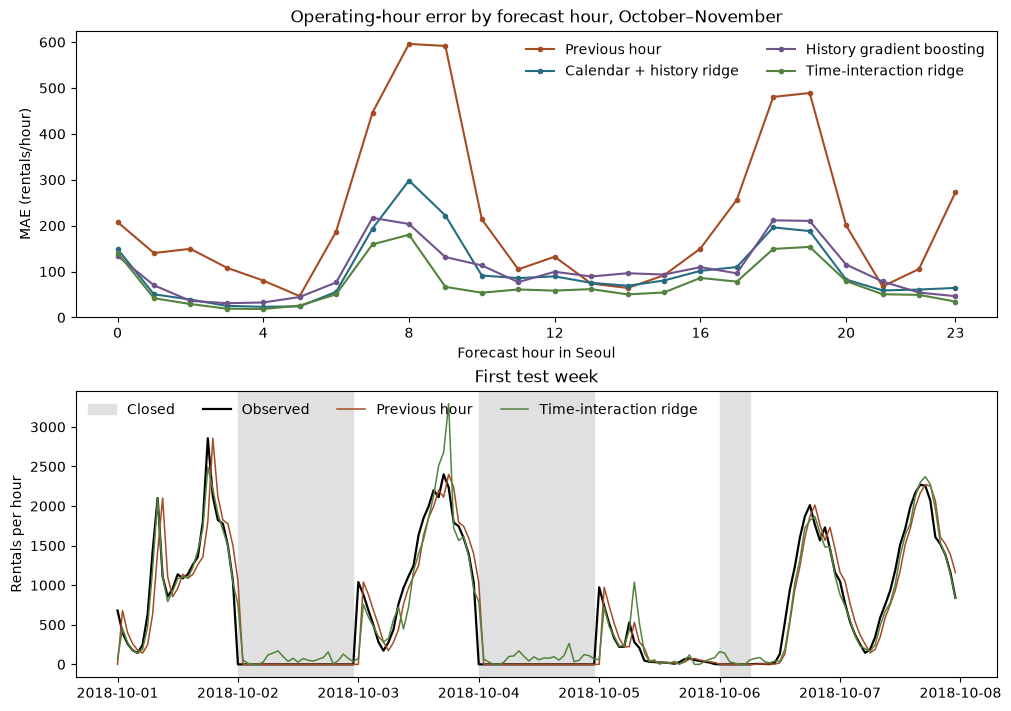

Operating-hour MAE at 08:00, 09:00, 18:00 and 19:00:


,Previous hour,Calendar + history ridge,History gradient boosting,Time-interaction ridge
time,,,,
8,596.1,298.4,203.7,180.1
9,591.6,222.1,131.6,66.6
18,480.6,196.3,211.6,149.3
19,489.1,188.2,210.4,153.8


In [13]:
shown = [
    "Previous hour",
    "Calendar + history ridge",
    "History gradient boosting",
    "Time-interaction ridge",
]
colors = dict(zip(shown, ["#a64c24", "#246c80", "#70528c", "#53833e"]))
open_hours = status.ne("Closed")
open_hourly_mae = test_errors.loc[open_hours, shown].groupby(test.index[open_hours].hour).mean()

fig, (by_hour, trace) = plt.subplots(2, 1, figsize=(10, 7), constrained_layout=True)
for name in shown:
    by_hour.plot(
        open_hourly_mae.index, open_hourly_mae[name], label=name, color=colors[name], marker="."
    )
by_hour.set(
    title="Operating-hour error by forecast hour, October–November",
    xlabel="Forecast hour in Seoul",
    ylabel="MAE (rentals/hour)",
)
by_hour.set_xticks([0, 4, 8, 12, 16, 20, 23])
by_hour.set_ylim(bottom=0)
by_hour.legend(frameon=False, ncol=2)

week = test.loc["2018-10-01":"2018-10-07"].index
trace.fill_between(
    week, 0, 1, where=~operating.loc[week], step="post", color="0.88",
    transform=trace.get_xaxis_transform(), label="Closed",
)
trace.plot(week, test.loc[week, "rentals"], color="black", linewidth=1.6, label="Observed")
for name in ["Previous hour", "Time-interaction ridge"]:
    forecast = test_predictions.loc[week, name]
    trace.plot(week, forecast, color=colors[name], linewidth=1.1, label=name)
trace.set(title="First test week", ylabel="Rentals per hour")
trace.legend(frameon=False, ncol=4, loc="upper left")
plt.show()

peak = [8, 9, 18, 19]
print("Operating-hour MAE at 08:00, 09:00, 18:00 and 19:00:")
open_hourly_mae.loc[peak].round(1)

The upper panel shows that the gain is concentrated in the commuting peaks. At 09:00, after the morning peak, time-interaction ridge misses 66.6 rentals per hour, compared with 131.6 for boosting, 222.1 for history ridge and 591.6 for the previous-hour baseline. This is the pattern seen on validation: a large 08:00 count signals a busy day but not an equally busy 09:00 on weekdays. The 08:00 and evening peaks remain the hardest hours for every method, because the count rises sharply from the previous hour.

The trace shows the two weaknesses directly. On the holiday of 3 October, time-interaction ridge applies the weekday evening slope to an afternoon that was already busy and forecasts 3,294 rentals at 18:00 against an observed 2,235. After each closure the history models begin the next day far too low, because the previous count is zero, and recover only once the first operating hour has been observed. On 5 October, with 35.5 mm of rain recorded, rentals fell to 4,522 for the day. The models followed the low counts from the previous hours but could not anticipate them, since weather during the forecast hour is not an input.

## Conclusion

On the 1,464 held-out hours of October and November, a ridge regression that lets the previous hour's count have a different slope for each clock hour and day type achieves an MAE of 73.8 rentals per hour. This is 63% below repeating the last count and 32% below a single-slope history ridge, with the same inputs. The validation ranking carried over to the test months, and the day-level resampling suggests the advantage is not driven by a few days.

The remaining errors have identifiable causes that the inputs cannot see:

1. **Operating status.** Closures and the first hour after reopening produce the largest individual misses. A known maintenance schedule could be added as an input if it were published in advance.
2. **Holidays.** The interaction groups treat holidays as weekdays. Grouping holidays with weekends is a natural next step, but it should be chosen on development data rather than on these test results.
3. **Weather.** Rain sharply reduced demand on 5 and 6 October. A weather forecast available at the start of the hour, unlike the measured weather in this file, could address this.

These results are for one city, one year and a one-hour horizon. Longer horizons would lose the previous-hour count that drives most of the improvement here.